# Flight Route Search: UCS vs A*
**OpenFlights dataset** | airport = node, route = edge, edge cost = haversine distance (km)

How to run: run the cells one by one from top to bottom (Shift + Enter). The first cell connects Google Drive, so `routes.csv` and `airports-extended.csv` must already be in `MyDrive/flight_project/`.

| Step | What happens |
|---|---|
| 1 | Connect Google Drive |
| 2 | Haversine distance function |
| 3 | Data loading and cleaning |
| 4 | Graph construction |
| 5 | UCS and A* |
| 6 | Run on any two airports |
| 7 | Experiments: 10 routes and 300 random pairs |
| 8 | Charts and maps |

## Step 1: Connect Google Drive

In [ ]:
import os

# Connect Google Drive (Colab will ask for permission the first time)
from google.colab import drive
drive.mount("/content/drive")

# Folder in Drive that already contains routes.csv and airports-extended.csv
DATA_DIR = "/content/drive/MyDrive/flight_project/"

need = ["routes.csv", "airports-extended.csv"]
print("Files in", DATA_DIR, ":", os.listdir(DATA_DIR))
missing = [f for f in need if not os.path.exists(DATA_DIR + f)]
assert not missing, f"Missing in Drive folder: {missing}"
print("OK: both CSV files found.")

Mounted at /content/drive
Files in /content/drive/MyDrive/flight_project/ : ['routes.csv', 'airports-extended.csv']
OK: both CSV files found.


## Step 2: Haversine distance
Computes the great-circle (straight-line over the Earth's surface) distance in km from the latitude/longitude of two airports. It is used both as the edge cost and as the A* heuristic.

In [ ]:
import heapq
import math
import time
import tracemalloc
from collections import defaultdict

import pandas as pd

AIRPORT_COLS = ["airport_id", "name", "city", "country", "iata", "icao", "lat", "lon",
                "altitude", "timezone", "dst", "tz_name", "type", "source"]
ROUTE_COLS = ["airline", "airline_id", "src", "src_id", "dst", "dst_id",
              "codeshare", "stops", "equipment"]
R_EARTH_KM = 6371.0088


def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between two (lat, lon) points in degrees."""
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi = p2 - p1
    dlmb = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dlmb / 2) ** 2
    return 2 * R_EARTH_KM * math.asin(math.sqrt(a))

## Step 3: Data loading and cleaning
- Read `\N` as missing; drop routes with a missing airport ID (423 rows)
- Convert IDs from float to int
- Remove self-loops (1 row)
- Keep each (source, destination) pair only once
- Attach lat/lon to every edge and compute its length in km

In [ ]:
def load_and_clean(base="", log=print):
    """Load both CSV files, clean them, return (nodes_df, edges_df, stats dict)."""
    airports = pd.read_csv(base + "airports-extended.csv", header=None,
                           names=AIRPORT_COLS, na_values=["\\N"])
    routes = pd.read_csv(base + "routes.csv", header=0,
                         names=ROUTE_COLS, na_values=["\\N"])
    stats = {"airports_raw": len(airports), "routes_raw": len(routes)}

    routes_clean = routes.dropna(subset=["src_id", "dst_id"]).copy()
    routes_clean["src_id"] = routes_clean["src_id"].astype(int)
    routes_clean["dst_id"] = routes_clean["dst_id"].astype(int)
    stats["routes_after_missing_id_drop"] = len(routes_clean)
    stats["missing_id_dropped"] = len(routes) - len(routes_clean)

    stats["self_loops"] = int((routes_clean["src_id"] == routes_clean["dst_id"]).sum())
    routes_clean = routes_clean[routes_clean["src_id"] != routes_clean["dst_id"]]
    stats["routes_after_self_loop_drop"] = len(routes_clean)

    edges = routes_clean[["src_id", "dst_id"]].drop_duplicates().reset_index(drop=True)
    stats["distinct_directed_pairs"] = len(edges)

    used_ids = set(edges["src_id"]) | set(edges["dst_id"])
    nodes = airports[airports["airport_id"].isin(used_ids)][
        ["airport_id", "iata", "name", "city", "country", "lat", "lon"]].copy()
    stats["airports_in_routes"] = len(used_ids)
    stats["airports_found_in_table"] = len(nodes)
    stats["duplicate_airport_ids"] = int(nodes["airport_id"].duplicated().sum())
    stats["missing_latlon"] = int(nodes[["lat", "lon"]].isna().sum().sum())

    src = nodes[["airport_id", "lat", "lon"]].rename(
        columns={"airport_id": "src_id", "lat": "src_lat", "lon": "src_lon"})
    dst = nodes[["airport_id", "lat", "lon"]].rename(
        columns={"airport_id": "dst_id", "lat": "dst_lat", "lon": "dst_lon"})
    edges = edges.merge(src, on="src_id", how="left").merge(dst, on="dst_id", how="left")
    stats["edges_after_merge"] = len(edges)
    stats["nan_after_merge"] = int(edges.isna().sum().sum())

    edges["km"] = [haversine(a, b, c, d) for a, b, c, d in
                   zip(edges.src_lat, edges.src_lon, edges.dst_lat, edges.dst_lon)]
    return nodes.reset_index(drop=True), edges, stats

In [ ]:
nodes, edges, stats = load_and_clean(DATA_DIR)
for k, v in stats.items():
    print(f"{k:32s} {v:,}")
edges.head()

airports_raw                     10,668
routes_raw                       67,663
routes_after_missing_id_drop     67,240
missing_id_dropped               423
self_loops                       1
routes_after_self_loop_drop      67,239
distinct_directed_pairs          37,273
airports_in_routes               3,330
airports_found_in_table          3,330
duplicate_airport_ids            0
missing_latlon                   0
edges_after_merge                37,273
nan_after_merge                  0


,src_id,dst_id,src_lat,src_lon,dst_lat,dst_lon,km
0,2965,2990,43.449902,39.956600,55.606201,49.278702,1506.827723
1,2966,2990,46.283298,48.006302,55.606201,49.278702,1040.439757
2,2966,2962,46.283298,48.006302,44.225101,43.081902,448.165528
3,2968,2990,55.305801,61.503300,55.606201,49.278702,770.509564
4,2968,4078,55.305801,61.503300,55.012600,82.650703,1338.633316


## Step 4: Graph construction
For every airport, a dictionary of neighbouring airports and distances. Every route is treated as bidirectional (undirected graph).

In [ ]:
def build_graph(nodes, edges, undirected=True):
    """Adjacency dict {airport_id: {neighbour_id: km}} and coords {id: (lat, lon)}."""
    coords = {int(r.airport_id): (r.lat, r.lon) for r in nodes.itertuples()}
    graph = defaultdict(dict)
    for r in edges.itertuples():
        graph[r.src_id][r.dst_id] = r.km
        if undirected:
            graph[r.dst_id][r.src_id] = r.km
    return dict(graph), coords


def components(graph):
    """Connected components (treating the graph as undirected). Returns list of sets."""
    seen, comps = set(), []
    for s in graph:
        if s in seen:
            continue
        comp, stack = {s}, [s]
        seen.add(s)
        while stack:
            u = stack.pop()
            for v in graph[u]:
                if v not in seen:
                    seen.add(v)
                    comp.add(v)
                    stack.append(v)
        comps.append(comp)
    return sorted(comps, key=len, reverse=True)

In [ ]:
graph, coords = build_graph(nodes, edges, undirected=True)
comps = components(graph)
print("Number of airports (nodes):", len(graph))
print("Number of undirected edges :", sum(len(v) for v in graph.values()) // 2)
print("Connected components       :", len(comps), [len(c) for c in comps])

Number of airports (nodes): 3330
Number of undirected edges : 19079
Connected components       : 7 [3304, 10, 4, 4, 4, 2, 2]


## Step 5: UCS and A*
Both algorithms share one function. `use_heuristic=False` gives UCS (f = g); `True` gives A* (f = g + h, where h is the haversine distance to the goal).

In [ ]:
def _reconstruct(parent, goal):
    path = [goal]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    return path[::-1]


def best_first(graph, coords, start, goal, use_heuristic, trace=None, return_explored=False):
    """UCS (use_heuristic=False) or A* (use_heuristic=True).

    f(n) = g(n) for UCS, f(n) = g(n) + h(n) for A*, with h = haversine(n, goal).
    Returns dict with path, cost, depth, nodes_expanded, nodes_generated, max_frontier.
    If `trace` is a list, one tuple (node, g, h, f, frontier_size) is appended per expansion.
    If return_explored is True, the explored set is added to the result under "explored".
    """
    glat, glon = coords[goal]

    def h(n):
        if not use_heuristic:
            return 0.0
        lat, lon = coords[n]
        return haversine(lat, lon, glat, glon)

    g = {start: 0.0}
    parent = {start: None}
    frontier = [(h(start), 0.0, start)]  # (f, g, node)
    explored = set()
    expanded = 0
    generated = 1
    max_frontier = 1

    while frontier:
        f, gn, node = heapq.heappop(frontier)
        if node in explored:
            continue  # stale entry (a cheaper path was already expanded)
        if node == goal:
            path = _reconstruct(parent, goal)
            out = {"path": path, "cost": gn, "depth": len(path) - 1,
                   "nodes_expanded": expanded, "nodes_generated": generated,
                   "max_frontier": max_frontier, "found": True}
            if return_explored:
                out["explored"] = explored
            return out
        explored.add(node)
        expanded += 1
        if trace is not None:
            trace.append((node, gn, f - gn, f, len(frontier)))
        for nb, w in graph.get(node, {}).items():
            if nb in explored:
                continue
            ng = gn + w
            if ng < g.get(nb, math.inf):
                g[nb] = ng
                parent[nb] = node
                heapq.heappush(frontier, (ng + h(nb), ng, nb))
                generated += 1
        max_frontier = max(max_frontier, len(frontier))

    out = {"path": None, "cost": math.inf, "depth": None, "nodes_expanded": expanded,
           "nodes_generated": generated, "max_frontier": max_frontier, "found": False}
    if return_explored:
        out["explored"] = explored
    return out


def measure(graph, coords, start, goal, use_heuristic, repeats=5):
    """Run one search; time = best of `repeats`, peak memory from tracemalloc (one run)."""
    best = math.inf
    for _ in range(repeats):
        t0 = time.perf_counter()
        res = best_first(graph, coords, start, goal, use_heuristic)
        best = min(best, time.perf_counter() - t0)
    tracemalloc.start()
    best_first(graph, coords, start, goal, use_heuristic)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    res["time_ms"] = best * 1000
    res["peak_mem_kb"] = peak / 1024
    return res

## Step 6: Run on any two airports of your choice

In [ ]:
airport_id = {r.iata: int(r.airport_id) for r in nodes.itertuples()}
airport_name = {int(r.airport_id): f"{r.iata} ({r.city})" for r in nodes.itertuples()}

def find_route(src, dst):
    s, t = airport_id[src], airport_id[dst]
    for name, use_h in (("UCS", False), ("A* ", True)):
        r = measure(graph, coords, s, t, use_h)
        if not r["found"]:
            print(f"{name}: no route, expanded {r['nodes_expanded']:,}")
            continue
        print(f"{name}: expanded {r['nodes_expanded']:>5,} | generated {r['nodes_generated']:>5,} | "
              f"{r['time_ms']:6.2f} ms | {r['peak_mem_kb']:6.1f} KB")
    print("path :", " > ".join(airport_name[x] for x in r["path"]))
    print(f"cost : {r['cost']:,.1f} km   depth: {r['depth']} flights")

find_route("DAC", "JFK")      # change the IATA codes here to try other airports

UCS: expanded 2,103 | generated 3,548 |   9.87 ms |  370.1 KB
A* : expanded    22 | generated   129 |   0.22 ms |   16.0 KB
path : DAC (Dhaka) > DEL (Delhi) > JFK (New York)
cost : 13,179.9 km   depth: 2 flights


## Step 7: Experiments (10 Dhaka routes, an unreachable case, 300 random pairs)

In [ ]:
import json
import random
import statistics

import pandas as pd


nodes, edges, stats = load_and_clean(DATA_DIR)
graph, coords = build_graph(nodes, edges, undirected=True)
comps = components(graph)
giant = comps[0]
by_iata = {r.iata: int(r.airport_id) for r in nodes.itertuples() if isinstance(r.iata, str)}
info = nodes.set_index("airport_id")


def code(i):
    return info.loc[i, "iata"]


# ---------- 1) named test pairs (all from Dhaka) ----------
dac = by_iata["DAC"]
named = ["CXB", "DXB", "SIN", "LHR", "JFK", "LAX", "SYD", "GRU", "JNB", "SCL"]
rows = []
paths = {}
for t in named:
    if t not in by_iata:
        print("missing", t)
        continue
    goal = by_iata[t]
    if goal not in giant:
        print("not in giant component", t)
        continue
    u = measure(graph, coords, dac, goal, use_heuristic=False)
    a = measure(graph, coords, dac, goal, use_heuristic=True)
    assert abs(u["cost"] - a["cost"]) < 1e-6, (t, u["cost"], a["cost"])
    straight = haversine(*coords[dac], *coords[goal])
    paths[t] = {"ucs": [code(x) for x in u["path"]], "astar": [code(x) for x in a["path"]]}
    rows.append({
        "pair": f"DAC-{t}", "straight_km": straight, "path_km": a["cost"],
        "depth": a["depth"], "path": " > ".join(paths[t]["astar"]),
        "ucs_expanded": u["nodes_expanded"], "astar_expanded": a["nodes_expanded"],
        "ucs_generated": u["nodes_generated"], "astar_generated": a["nodes_generated"],
        "ucs_frontier": u["max_frontier"], "astar_frontier": a["max_frontier"],
        "ucs_ms": u["time_ms"], "astar_ms": a["time_ms"],
        "ucs_kb": u["peak_mem_kb"], "astar_kb": a["peak_mem_kb"],
        "same_path": u["path"] == a["path"],
    })
named_df = pd.DataFrame(rows)
named_df["expanded_reduction_pct"] = 100 * (1 - named_df.astar_expanded / named_df.ucs_expanded)
named_df.to_csv("results_named_pairs.csv", index=False)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(named_df[["pair", "straight_km", "path_km", "depth", "ucs_expanded", "astar_expanded",
                "expanded_reduction_pct", "ucs_ms", "astar_ms", "ucs_kb", "astar_kb",
                "same_path"]].round(2).to_string(index=False))
print(named_df[["pair", "path"]].to_string(index=False))

# ---------- 2) no-path case ----------
small = comps[1]
goal = next(iter(small))
u = best_first(graph, coords, dac, goal, False)
a = best_first(graph, coords, dac, goal, True)
nopath = {"goal": code(goal), "ucs_found": u["found"], "ucs_expanded": u["nodes_expanded"],
          "astar_found": a["found"], "astar_expanded": a["nodes_expanded"]}
print("no-path case:", nopath)

# ---------- 3) random pairs ----------
random.seed(42)
giant_list = sorted(giant)
N = 300
rand_rows = []
for _ in range(N):
    s, t = random.sample(giant_list, 2)
    u = best_first(graph, coords, s, t, False)
    a = best_first(graph, coords, s, t, True)
    assert abs(u["cost"] - a["cost"]) < 1e-6
    rand_rows.append({"src": code(s), "dst": code(t), "cost": a["cost"], "depth": a["depth"],
                      "ucs_expanded": u["nodes_expanded"], "astar_expanded": a["nodes_expanded"]})
rdf = pd.DataFrame(rand_rows)
rdf["reduction_pct"] = 100 * (1 - rdf.astar_expanded / rdf.ucs_expanded)
rdf.to_csv("results_random_pairs.csv", index=False)
summary = {
    "n_pairs": N,
    "mean_ucs_expanded": rdf.ucs_expanded.mean(),
    "mean_astar_expanded": rdf.astar_expanded.mean(),
    "median_ucs_expanded": rdf.ucs_expanded.median(),
    "median_astar_expanded": rdf.astar_expanded.median(),
    "mean_reduction_pct": rdf.reduction_pct.mean(),
    "overall_reduction_pct": 100 * (1 - rdf.astar_expanded.sum() / rdf.ucs_expanded.sum()),
    "mean_cost_km": rdf.cost.mean(), "mean_depth": rdf.depth.mean(),
    "max_depth": int(rdf.depth.max()),
    "astar_never_worse": bool((rdf.astar_expanded <= rdf.ucs_expanded).all()),
}
print(json.dumps(summary, indent=1))

# ---------- 4) independent check of optimality with scipy Dijkstra ----------
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
ids = sorted(graph)
idx = {n: i for i, n in enumerate(ids)}
r, c, w = [], [], []
for u_, nb in graph.items():
    for v_, km in nb.items():
        r.append(idx[u_]); c.append(idx[v_]); w.append(km)
M = csr_matrix((w, (r, c)), shape=(len(ids), len(ids)))
bad = 0
for row in rand_rows[:100]:
    s, t = by_iata[row["src"]], by_iata[row["dst"]]
    d = dijkstra(M, directed=True, indices=idx[s])[idx[t]]
    if abs(d - row["cost"]) > 1e-6:
        bad += 1
for row in named_df.itertuples():
    t = by_iata[row.pair.split("-")[1]]
    d = dijkstra(M, directed=True, indices=idx[dac])[idx[t]]
    if abs(d - row.path_km) > 1e-6:
        bad += 1
print("scipy Dijkstra disagreements:", bad)

json.dump({"stats": stats, "named": rows, "nopath": nopath, "random_summary": summary,
           "paths": paths, "scipy_disagreements": bad,
           "components": [len(x) for x in comps]},
          open("results.json", "w"), indent=1, default=float)

   pair  straight_km  path_km  depth  ucs_expanded  astar_expanded  expanded_reduction_pct  ucs_ms  astar_ms  ucs_kb  astar_kb  same_path
DAC-CXB       310.67   310.67      1             8               1                   87.50    0.08      0.10    6.78      3.49       True
DAC-DXB      3536.94  3536.94      1           390               1                   99.74    3.08      0.09  101.82      3.49       True
DAC-SIN      2898.24  2898.24      1           289               1                   99.65    2.01      0.09   69.96      3.49       True
DAC-LHR      8014.99  8014.99      1          1367               1                   99.93   11.12      0.09  370.09      3.49       True
DAC-JFK     12660.49 13179.91      2          2103              22                   98.95   16.14      0.42  370.09     15.98       True
DAC-LAX     12904.44 13407.26      3          2159              20                   99.07   17.37      0.96  370.09     35.11       True
DAC-SYD      9082.56  9082.97     

## Step 8: Charts and maps
The figures for the report and poster are generated here. They are saved as `fig_*.png` and appear in the Files panel on the left.

In [ ]:
import math

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Poster palette: #000000 #134074 #9bc4df #eef4f8 #b3d3e8 #ffffff #f3f8f4
SURFACE = "#eef4f8"                 # same as the poster panels, so figures blend in
INK, INK2, MUTED = "#000000", "#134074", "#134074"
GRID, BASE = "#b3d3e8", "#9bc4df"   # grid lines / axes
UCS_C, AST_C = "#9bc4df", "#134074" # UCS = light blue, A* = navy (A* is the hero colour)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": BASE, "axes.linewidth": 1, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

nodes, edges, stats = load_and_clean(DATA_DIR)
graph, coords = build_graph(nodes, edges, undirected=True)
info = nodes.set_index("airport_id")
by_iata = {r.iata: int(r.airport_id) for r in nodes.itertuples()}
named = pd.read_csv("results_named_pairs.csv")
rand = pd.read_csv("results_random_pairs.csv")


def legend(ax, loc="lower right"):
    ax.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=UCS_C, mec=AST_C, mew=0.7, ms=9, label="UCS"),
                       plt.Line2D([], [], marker="s", ls="", color=AST_C, ms=9, label="A*")],
              frameon=False, loc=loc, labelcolor=INK2)


# ---------------------------------------------------------------- fig 1: nodes expanded
fig, ax = plt.subplots(figsize=(9, 5.6), dpi=200)
pairs = list(named.pair)[::-1]
y = np.arange(len(pairs))
h = 0.34
u = named.set_index("pair").loc[pairs, "ucs_expanded"].values
a = named.set_index("pair").loc[pairs, "astar_expanded"].values
LEFT = 0.5
ax.barh(y + h / 2 + 0.01, u - LEFT, h, left=LEFT, color=UCS_C, edgecolor=AST_C, linewidth=0.7)
ax.barh(y - h / 2 - 0.01, a - LEFT, h, left=LEFT, color=AST_C)
ax.set_xscale("log")
ax.set_xlim(LEFT, 9000)
ax.set_yticks(y, pairs, color=INK2)
ax.set_xlabel("Nodes expanded (log scale)")
ax.xaxis.grid(True)
ax.tick_params(length=0)
ax.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
ax.minorticks_off()
top = len(pairs) - 1  # DAC-CXB is last in reversed list -> index 0; label the largest (SCL) = top
for yy, uu, aa, p in zip(y, u, a, pairs):
    if p == "DAC-SCL":
        ax.text(uu * 1.12, yy + h / 2 + 0.01, f"{uu:,}", va="center", color=INK2, fontsize=10)
        ax.text(aa * 1.12, yy - h / 2 - 0.01, f"{aa:,}", va="center", color=INK2, fontsize=10)
legend(ax, "upper right")
ax.set_title("Nodes expanded: UCS vs A* (Dhaka to 10 airports)", loc="left", color=INK, pad=12)
fig.tight_layout()
fig.savefig("fig_nodes_expanded.png")
plt.close(fig)

# ---------------------------------------------------------------- fig 2: time + memory
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=200)
for ax, (ucol, acol, title, unit) in zip(
        axes, [("ucs_ms", "astar_ms", "Execution time", "milliseconds"),
               ("ucs_kb", "astar_kb", "Peak memory", "KB")]):
    pr = list(named.pair)[::-1]
    yy = np.arange(len(pr))
    uu = named.set_index("pair").loc[pr, ucol].values
    aa = named.set_index("pair").loc[pr, acol].values
    ax.barh(yy + h / 2 + 0.01, uu, h, color=UCS_C, edgecolor=AST_C, linewidth=0.7)
    ax.barh(yy - h / 2 - 0.01, aa, h, color=AST_C)
    ax.set_yticks(yy, pr if ax is axes[0] else [], color=INK2)
    ax.set_xlabel(unit)
    ax.xaxis.grid(True)
    ax.tick_params(length=0)
    ax.set_title(title, loc="left", color=INK, pad=10)
    for y_, u_, a_, p in zip(yy, uu, aa, pr):
        if p == "DAC-SCL":
            ax.text(u_ * 1.02, y_ + h / 2 + 0.01, f"{u_:.1f}", va="center", color=INK2, fontsize=10)
            ax.text(a_ * 1.02 + (uu.max() * 0.01), y_ - h / 2 - 0.01, f"{a_:.1f}", va="center",
                    color=INK2, fontsize=10)
legend(axes[0], "upper right")
fig.tight_layout()
fig.savefig("fig_time_memory.png")
plt.close(fig)

# ---------------------------------------------------------------- fig 3: random pairs scatter
fig, ax = plt.subplots(figsize=(6.4, 5.6), dpi=200)
ax.scatter(rand.ucs_expanded, rand.astar_expanded, s=34, color=AST_C, edgecolor=SURFACE,
           linewidth=0.8, zorder=3)
lim = [1, 4000]
ax.plot(lim, lim, color=BASE, lw=1.4, zorder=2)
ax.text(1.4, 1.7, "equal effort (A* = UCS)", color=MUTED, fontsize=9.5, rotation=39,
        rotation_mode="anchor", va="bottom")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lim)
ax.set_ylim(0.8, 4000)
ax.set_xlabel("UCS nodes expanded")
ax.set_ylabel("A* nodes expanded")
ax.grid(True)
ax.tick_params(length=0)
ax.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
ax.set_yticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
ax.minorticks_off()
ax.set_title("300 random airport pairs: every point is below the line", loc="left", color=INK,
             pad=12, fontsize=11.5)
fig.tight_layout()
fig.savefig("fig_random_scatter.png")
plt.close(fig)


# ---------------------------------------------------------------- world-map helpers
def world(ax, ghost=GRID):
    ax.scatter(nodes.lon, nodes.lat, s=5, color=ghost, linewidths=0, zorder=1)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-60, 80)
    ax.set_aspect("equal")
    ax.axis("off")


def gc_segments(p, q, n=60):
    """Great-circle arc from p=(lat,lon) to q, split where it crosses the date line."""
    la1, lo1, la2, lo2 = map(math.radians, (*p, *q))
    v1 = np.array([math.cos(la1) * math.cos(lo1), math.cos(la1) * math.sin(lo1), math.sin(la1)])
    v2 = np.array([math.cos(la2) * math.cos(lo2), math.cos(la2) * math.sin(lo2), math.sin(la2)])
    om = math.acos(max(-1, min(1, float(v1 @ v2))))
    pts = []
    for t in np.linspace(0, 1, n):
        v = (math.sin((1 - t) * om) * v1 + math.sin(t * om) * v2) / math.sin(om)
        pts.append((math.degrees(math.atan2(v[1], v[0])), math.degrees(math.asin(v[2]))))
    segs, cur = [], [pts[0]]
    for a_, b_ in zip(pts[:-1], pts[1:]):
        if abs(b_[0] - a_[0]) > 180:
            segs.append(cur)
            cur = []
        cur.append(b_)
    segs.append(cur)
    return segs


def draw_path(ax, path, color, lw=2.0, zorder=4):
    for u_, v_ in zip(path[:-1], path[1:]):
        for seg in gc_segments(coords[u_], coords[v_]):
            xs, ys = zip(*seg)
            ax.plot(xs, ys, color=color, lw=lw, solid_capstyle="round", zorder=zorder)


# ---------------------------------------------------------------- fig 4: search process
start, goal = by_iata["DAC"], by_iata["SCL"]
res = {}
for name, use_h in (("UCS", False), ("A*", True)):
    res[name] = best_first(graph, coords, start, goal, use_h, return_explored=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.7), dpi=200)
for ax, name, col in zip(axes, ("UCS", "A*"), (UCS_C, AST_C)):
    world(ax, ghost="#ffffff")
    ex = list(res[name]["explored"])
    ax.scatter([coords[i][1] for i in ex], [coords[i][0] for i in ex], s=12, color=col,
               edgecolor=AST_C, linewidth=0.4, zorder=2)
    draw_path(ax, res[name]["path"], INK, lw=2.0)
    for node, lab, dx, dy, ha in ((start, "DAC", 6, 5, "left"), (goal, "SCL", -6, -12, "right")):
        ax.scatter([coords[node][1]], [coords[node][0]], s=70, color=INK, edgecolor=SURFACE,
                   linewidth=2, zorder=6)
        ax.text(coords[node][1] + dx, coords[node][0] + dy, lab, color=INK, fontsize=10,
                ha=ha, zorder=7)
    ax.set_title(f"{name}: {res[name]['nodes_expanded']:,} airports expanded", loc="left",
                 color=INK, fontsize=12)
fig.tight_layout()
fig.savefig("fig_search_process.png")
plt.close(fig)

# ---------------------------------------------------------------- fig 5: solution routes
fig, ax = plt.subplots(figsize=(12, 5.0), dpi=200)
world(ax)
for t in ["JFK", "LAX", "SYD", "GRU", "SCL", "JNB"]:
    goal = by_iata[t]
    r = best_first(graph, coords, start, goal, True)
    draw_path(ax, r["path"], AST_C, lw=1.8)
    for n_ in r["path"][1:-1]:
        ax.scatter([coords[n_][1]], [coords[n_][0]], s=26, color=AST_C, edgecolor=SURFACE,
                   linewidth=1.2, zorder=5)
    ax.scatter([coords[goal][1]], [coords[goal][0]], s=70, color=AST_C, edgecolor=SURFACE,
               linewidth=2, zorder=6)
    ax.text(coords[goal][1] + 4, coords[goal][0] + 4, t, color=INK, fontsize=10, zorder=7)
ax.scatter([coords[by_iata["DAC"]][1]], [coords[by_iata["DAC"]][0]], s=90, color=INK,
           edgecolor=SURFACE, linewidth=2, zorder=8)
ax.text(coords[by_iata["DAC"]][1] + 4, coords[by_iata["DAC"]][0] + 5, "DAC", color=INK,
        fontsize=10.5, zorder=9)
ax.set_title("Shortest routes found from Dhaka (A*, identical to UCS)", loc="left", color=INK,
             fontsize=12)
fig.tight_layout()
fig.savefig("fig_routes_map.png")
plt.close(fig)
print("figures done")

figures done


In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


# Poster palette: #000000 #134074 #9bc4df #eef4f8 #b3d3e8 #ffffff #f3f8f4
SURFACE, INK, INK2, GRID, BASE = "#eef4f8", "#000000", "#134074", "#b3d3e8", "#9bc4df"
NAVY, LIGHT = "#134074", "#9bc4df"
plt.rcParams.update({"figure.facecolor": SURFACE, "savefig.facecolor": SURFACE, "font.size": 11})


def box(ax, x, y, w, h, text, fc="#ffffff", ec=BASE, bold=False):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.4, zorder=2))
    ax.text(x, y, text, ha="center", va="center", color=INK, zorder=3,
            fontweight="bold" if bold else "normal", fontsize=10.5)


def arrow(ax, p, q, label=None, lab_xy=None):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.4,
                                                   shrinkA=0, shrinkB=0), zorder=1)
    if label:
        ax.text(*lab_xy, label, color=INK2, fontsize=10, ha="center", va="center",
                bbox=dict(fc=SURFACE, ec="none", pad=1))


# ---------------- flowchart ----------------
fig, ax = plt.subplots(figsize=(8.4, 6.8), dpi=200)
ax.set_xlim(0, 10); ax.set_ylim(0, 8.2); ax.axis("off")
cx = 4.4
Y = dict(start=7.7, init=6.7, empty=5.7, pop=4.75, expl=3.8, goal=2.85, add=1.45)
box(ax, cx, Y["start"], 5.0, 0.6, "Start: source S, goal G", fc="#b3d3e8", ec=NAVY, bold=True)
box(ax, cx, Y["init"], 5.6, 0.8, "frontier = priority queue {(f(S), S)}\nexplored = {}   g(S) = 0")
box(ax, cx, Y["empty"], 4.0, 0.6, "Frontier empty?", fc="#f3f8f4", ec=NAVY)
box(ax, cx, Y["pop"], 5.0, 0.6, "Pop node n with the smallest f(n)")
box(ax, cx, Y["expl"], 4.0, 0.6, "n already explored?", fc="#f3f8f4", ec=NAVY)
box(ax, cx, Y["goal"], 4.0, 0.6, "n == goal G?", fc="#f3f8f4", ec=NAVY)
box(ax, cx, Y["add"], 6.6, 1.4, "Add n to explored (nodes expanded + 1)\nfor each neighbour m with cost w:\nif g(n)+w < g(m): update g(m), parent(m)=n,\npush (g(m)+h(m), m)")
box(ax, 8.6, Y["empty"], 2.0, 0.8, "FAILURE\n(no route)", fc="#ffffff")
box(ax, 8.6, Y["goal"], 2.0, 1.0, "SUCCESS\nrebuild path\nvia parent", fc="#b3d3e8", ec=NAVY, bold=True)
def vs(y1, y2, lab=None):
    arrow(ax, (cx, y1), (cx, y2), lab, (cx + 0.35, (y1 + y2) / 2) if lab else None)
vs(Y["start"] - 0.3, Y["init"] + 0.4); vs(Y["init"] - 0.4, Y["empty"] + 0.3)
vs(Y["empty"] - 0.3, Y["pop"] + 0.3, "No"); vs(Y["pop"] - 0.3, Y["expl"] + 0.3)
vs(Y["expl"] - 0.3, Y["goal"] + 0.3, "No"); vs(Y["goal"] - 0.3, Y["add"] + 0.7, "No")
arrow(ax, (cx + 2.0, Y["empty"]), (7.6, Y["empty"]), "Yes", (6.8, Y["empty"] + 0.22))
arrow(ax, (cx + 2.0, Y["goal"]), (7.6, Y["goal"]), "Yes", (6.8, Y["goal"] + 0.22))
rail = 0.9
ax.plot([cx - 2.0, rail], [Y["expl"], Y["expl"]], color=INK2, lw=1.4, zorder=1)
ax.plot([cx - 3.3, rail], [Y["add"], Y["add"]], color=INK2, lw=1.4, zorder=1)
ax.plot([rail, rail], [Y["add"], Y["empty"]], color=INK2, lw=1.4, zorder=1)
arrow(ax, (rail, Y["empty"]), (cx - 2.0, Y["empty"]))
ax.text(0.1, Y["expl"] + 0.1, "Yes\n(skip)", color=INK2, fontsize=10)
ax.text(0.1, Y["add"] + 0.15, "repeat", color=INK2, fontsize=10)
ax.text(0.3, 0.2, "UCS:  f(n) = g(n)          A*:  f(n) = g(n) + h(n),  h = haversine(n, G)", color=INK, fontsize=10.5)
fig.tight_layout(); fig.savefig("fig_flowchart.png"); plt.close(fig)

# ---------------- state-space graph (real values) ----------------
nodes, edges, _ = load_and_clean(DATA_DIR)
g, c = build_graph(nodes, edges)
by = {r.iata: int(r.airport_id) for r in nodes.itertuples()}
d = lambda a, b: g[by[a]][by[b]]
fig, ax = plt.subplots(figsize=(9.2, 4.8), dpi=200)
ax.set_xlim(0, 10); ax.set_ylim(-0.4, 5.6); ax.axis("off")
pos = {"DAC": (1.0, 2.8), "DEL": (5.0, 4.4), "DXB": (5.0, 1.2), "KMG": (3.3, 2.8), "JFK": (9.0, 2.8), "PEK": (7.0, 2.8)}
edges_show = [("DAC", "DEL"), ("DEL", "JFK"), ("DAC", "KMG"), ("KMG", "PEK"), ("PEK", "JFK"), ("DAC", "DXB"), ("DXB", "JFK")]
for a, b in edges_show:
    (x1, y1), (x2, y2) = pos[a], pos[b]
    best = (a, b) in [("DAC", "DEL"), ("DEL", "JFK")]
    ax.plot([x1, x2], [y1, y2], color=NAVY if best else BASE, lw=3 if best else 1.6, zorder=1)
    w = d(a, b)  # real edge (asserted by KeyError otherwise)
    ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.22, f"{w:,.0f} km", ha="center", color=INK2, fontsize=9.5,
            bbox=dict(fc=SURFACE, ec="none", pad=1), zorder=3)
for k, (x, y) in pos.items():
    col = INK if k in ("DAC", "JFK") else "#ffffff"
    ax.scatter([x], [y], s=900, color=col, edgecolor=NAVY if k in ("DEL",) else BASE, linewidth=2, zorder=4)
    ax.text(x, y, k, ha="center", va="center", color="#ffffff" if k in ("DAC", "JFK") else INK, fontsize=10.5,
            fontweight="bold", zorder=5)
ax.text(0.2, -0.1, "Edges are real routes from the data (cost = km).  Blue = optimal: DAC > DEL > JFK = 13,180 km.\nAlternatives: via KMG, PEK = 14,348 km;  via DXB = 14,539 km.",
        color=INK2, fontsize=10)
fig.tight_layout(); fig.savefig("fig_state_space.png"); plt.close(fig)
print("ok")

ok


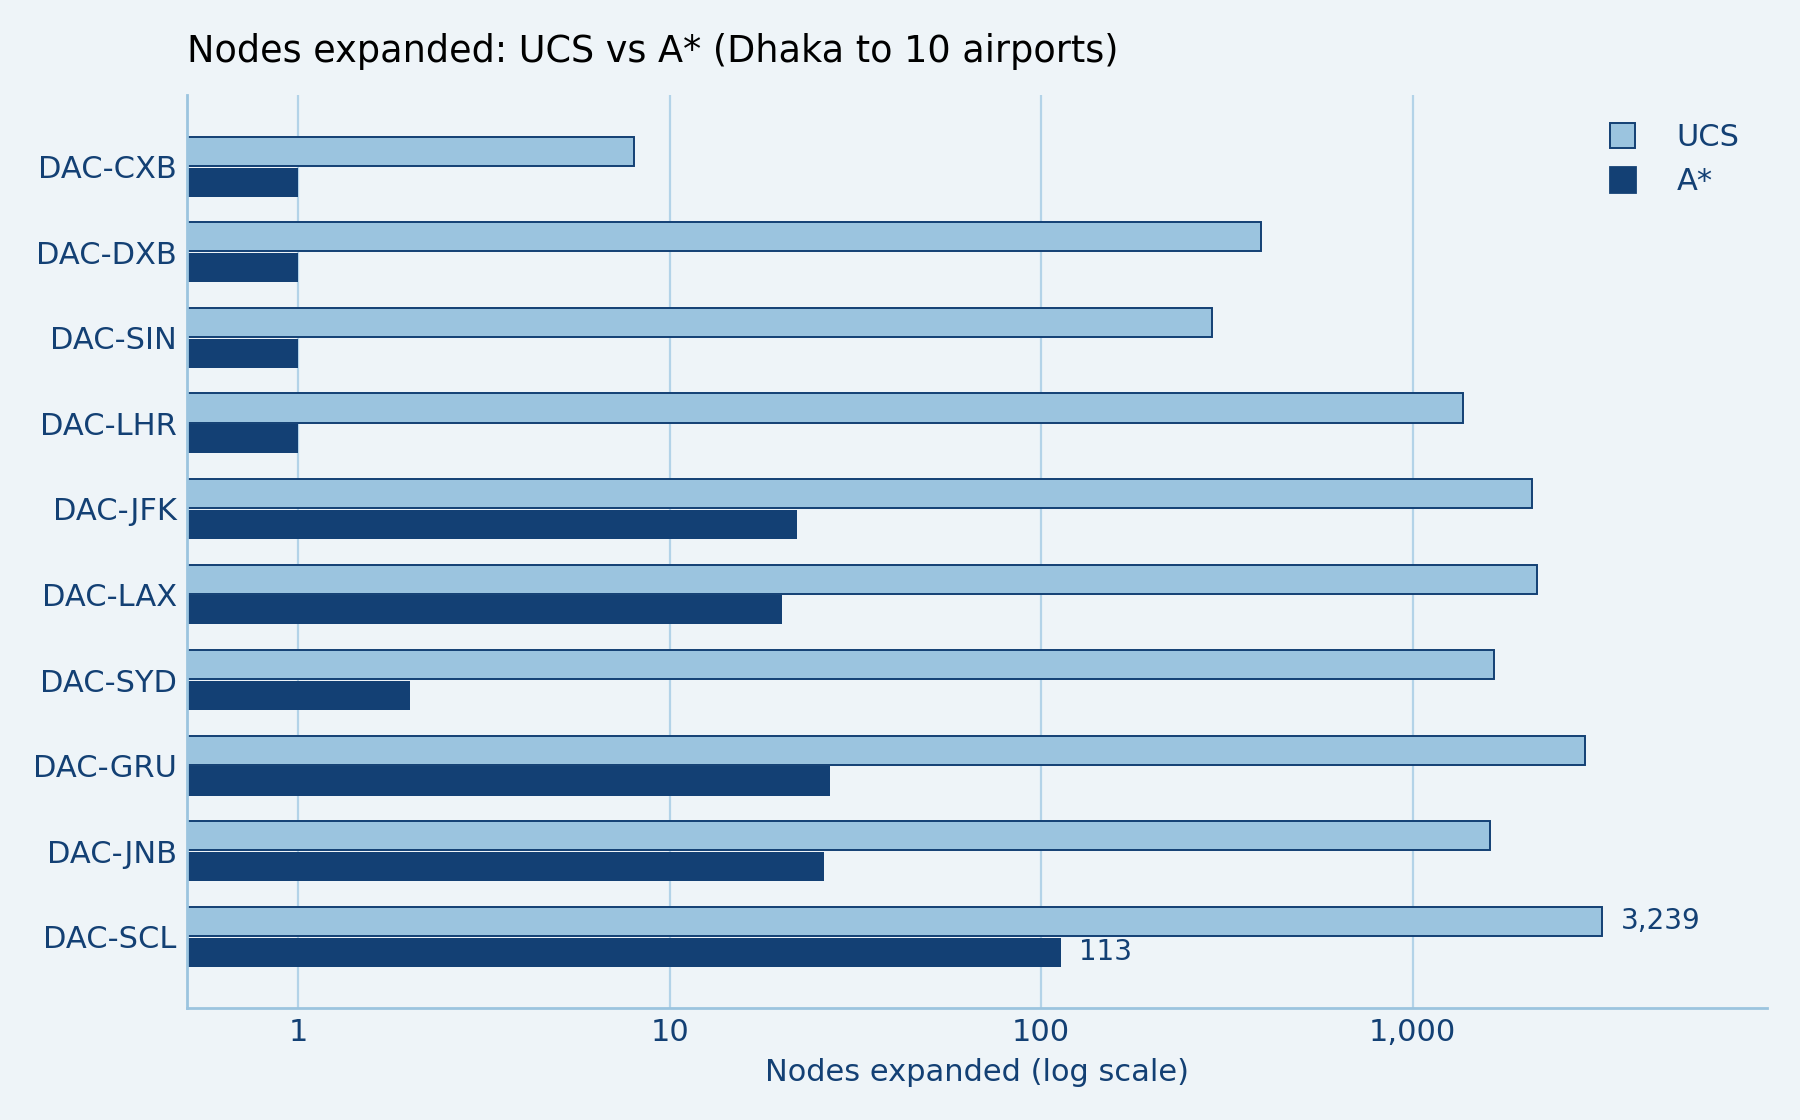

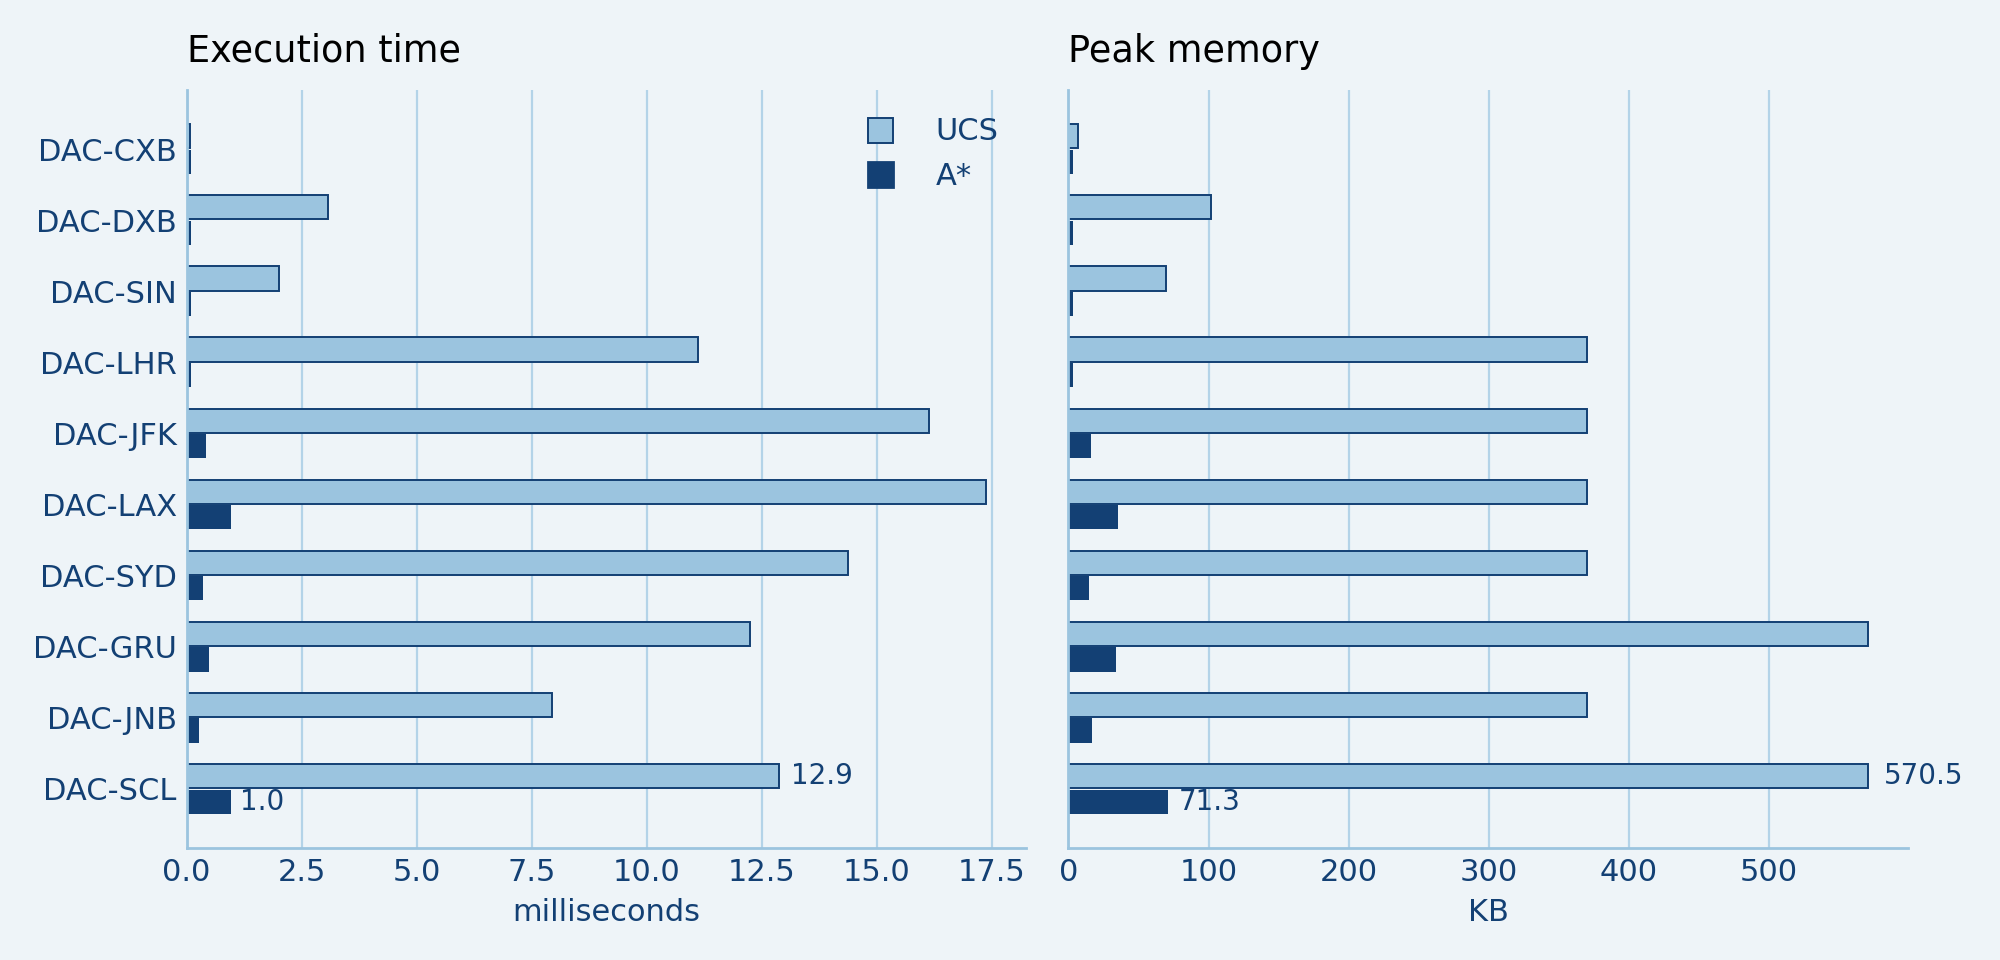

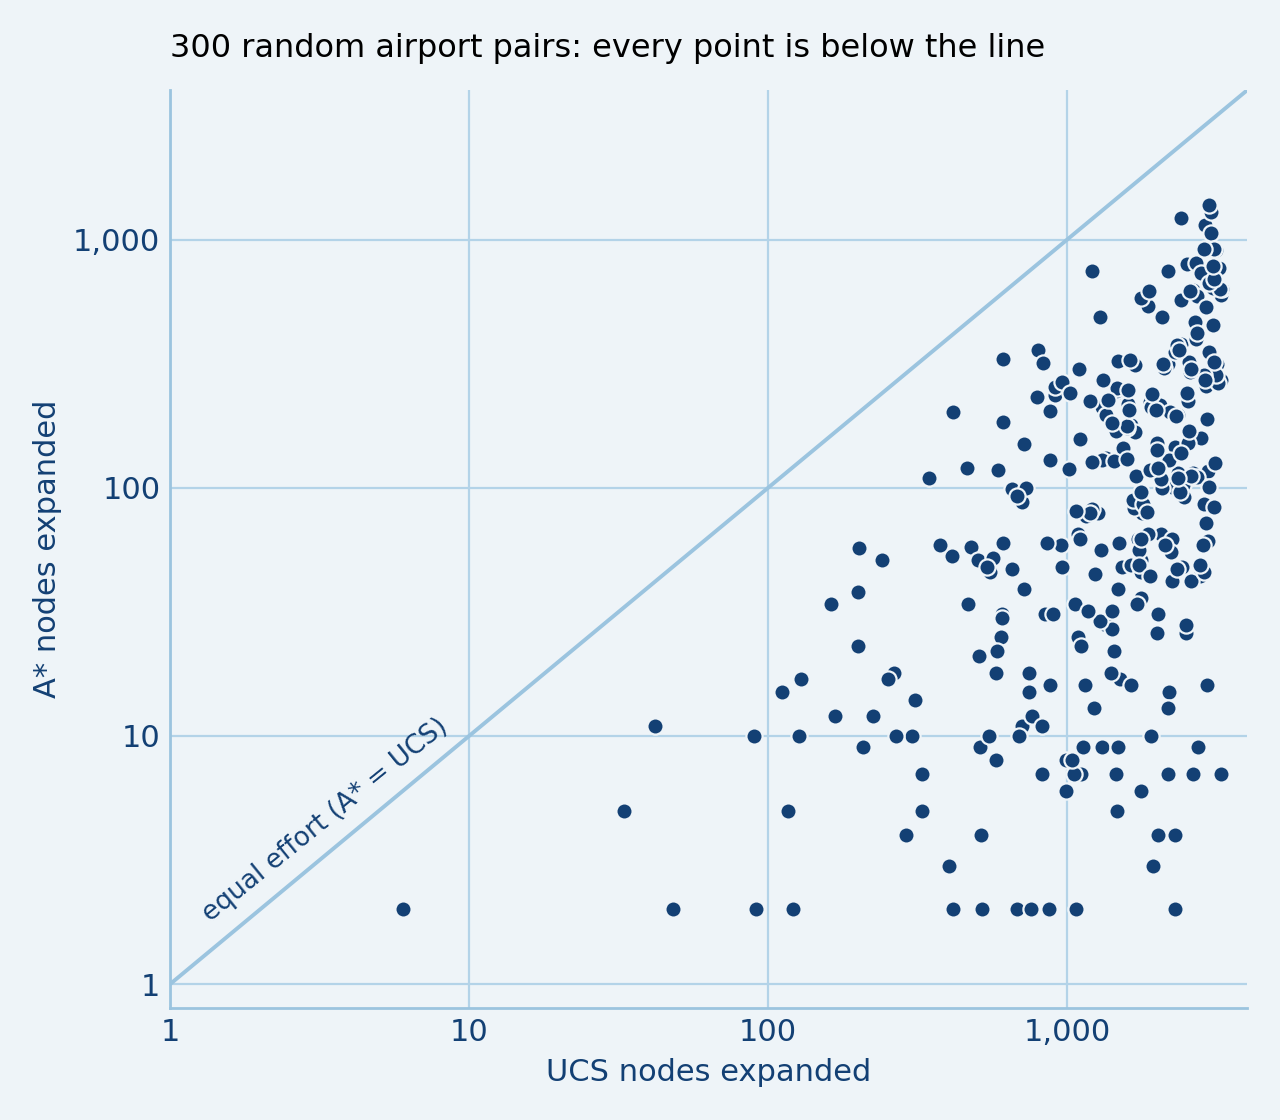

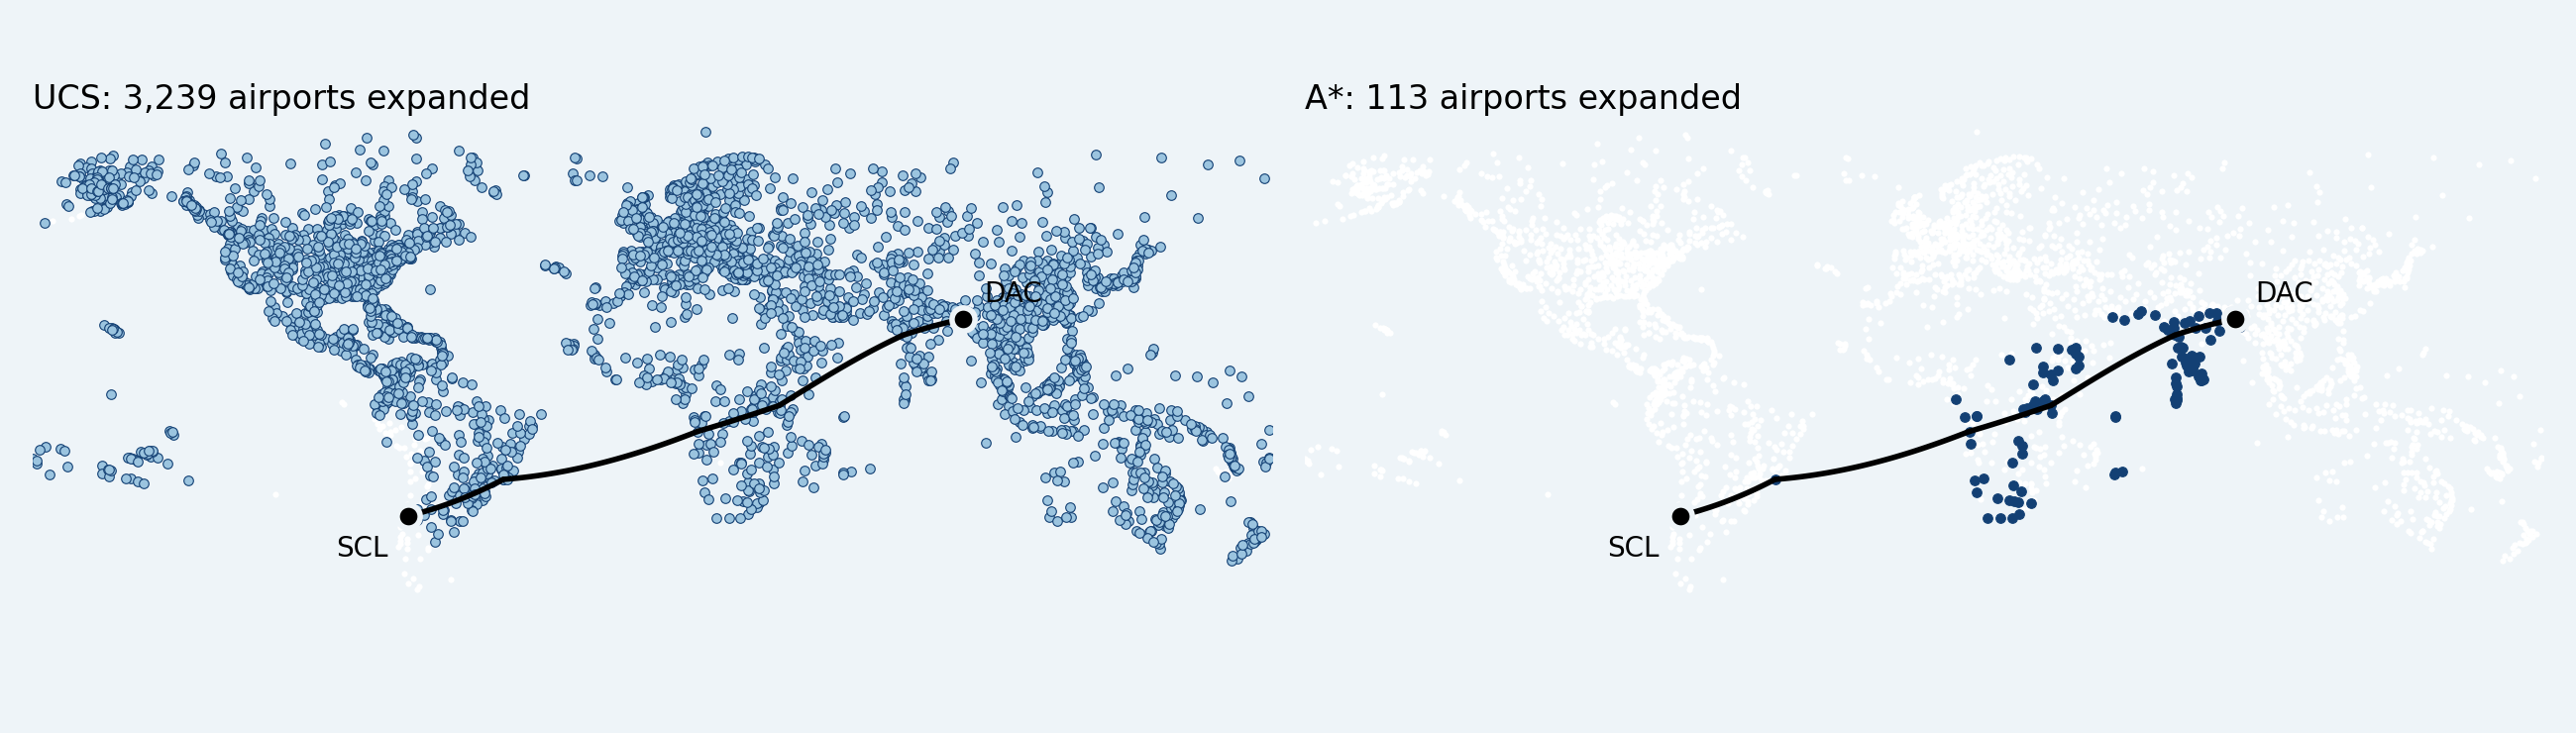

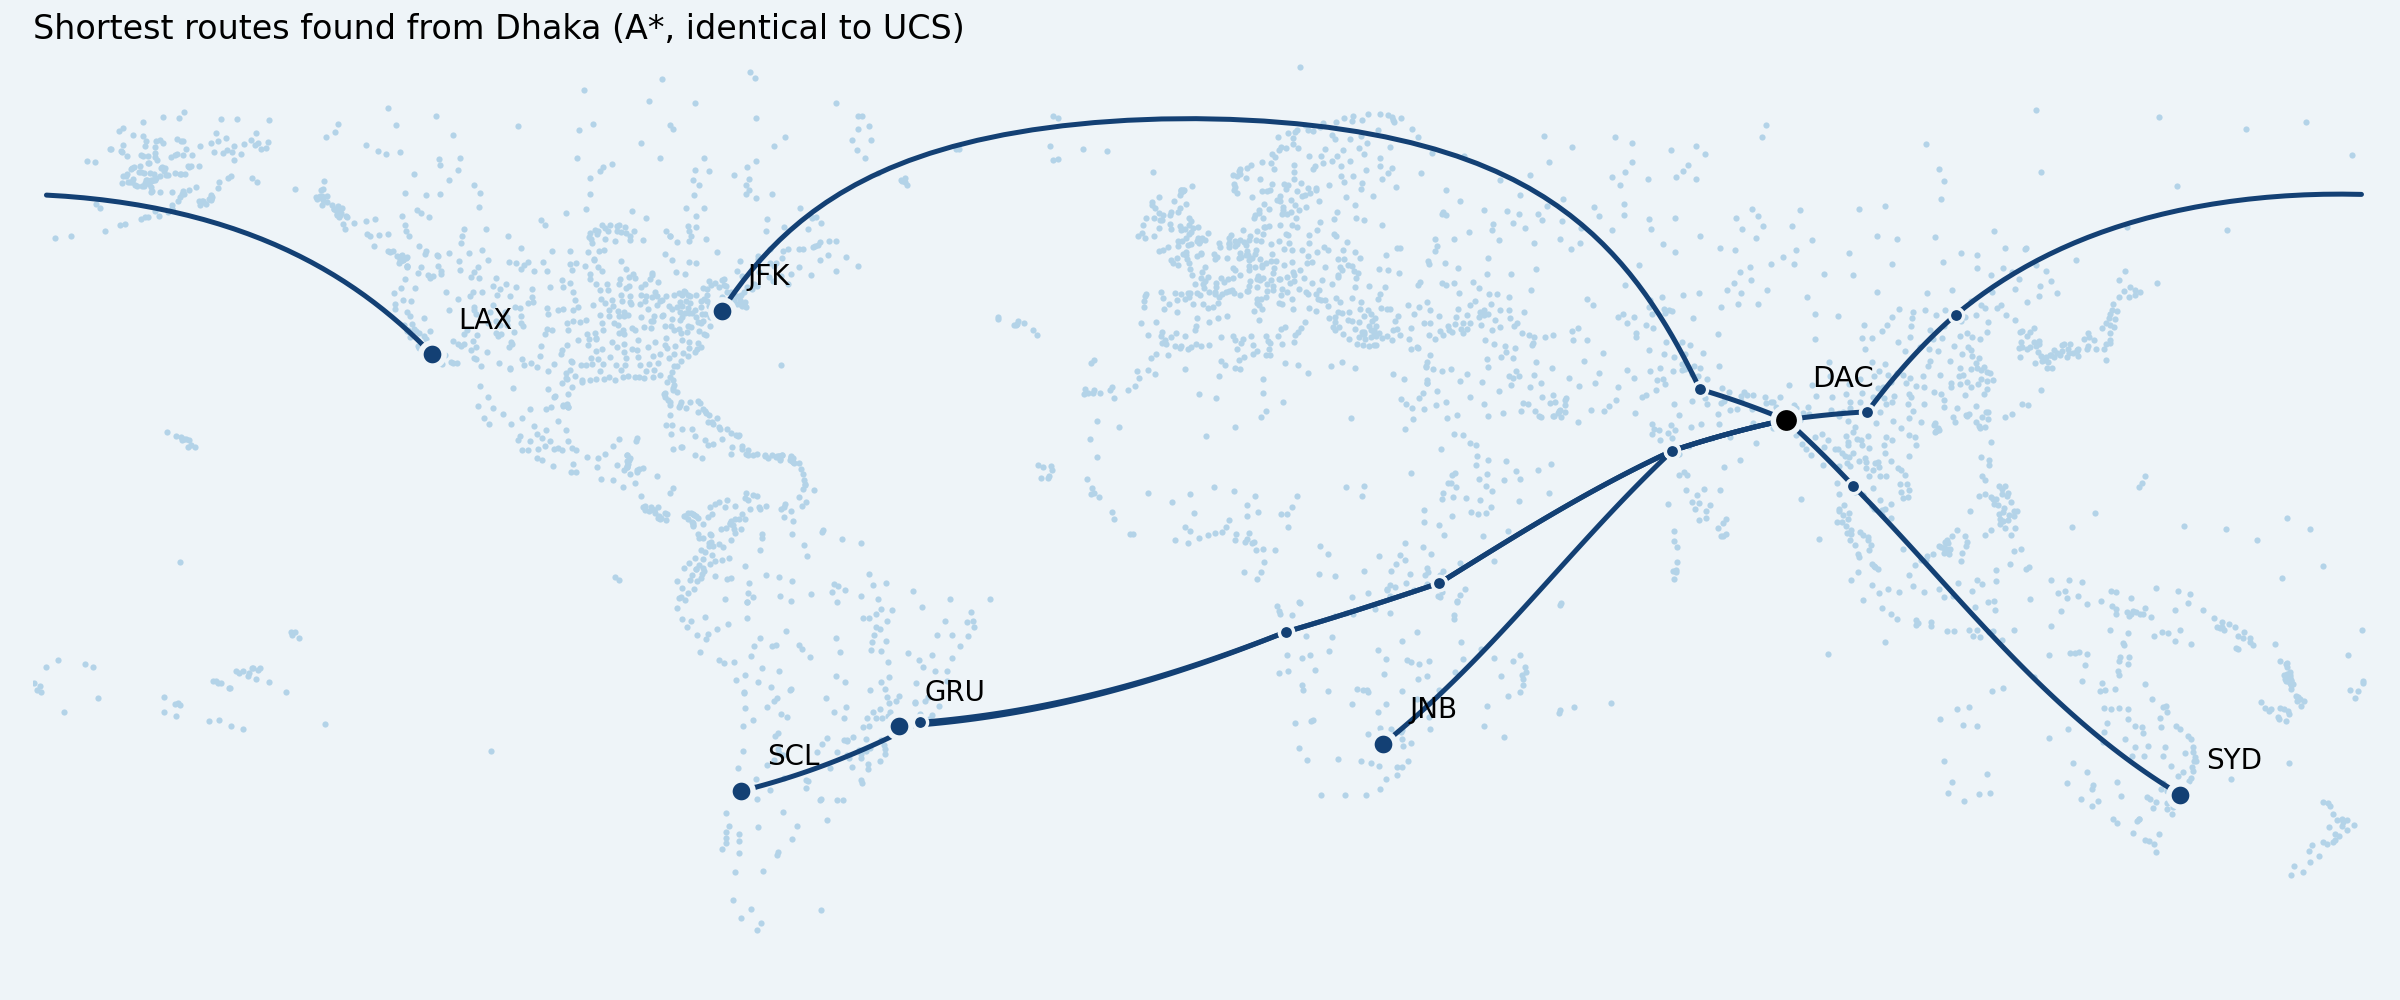

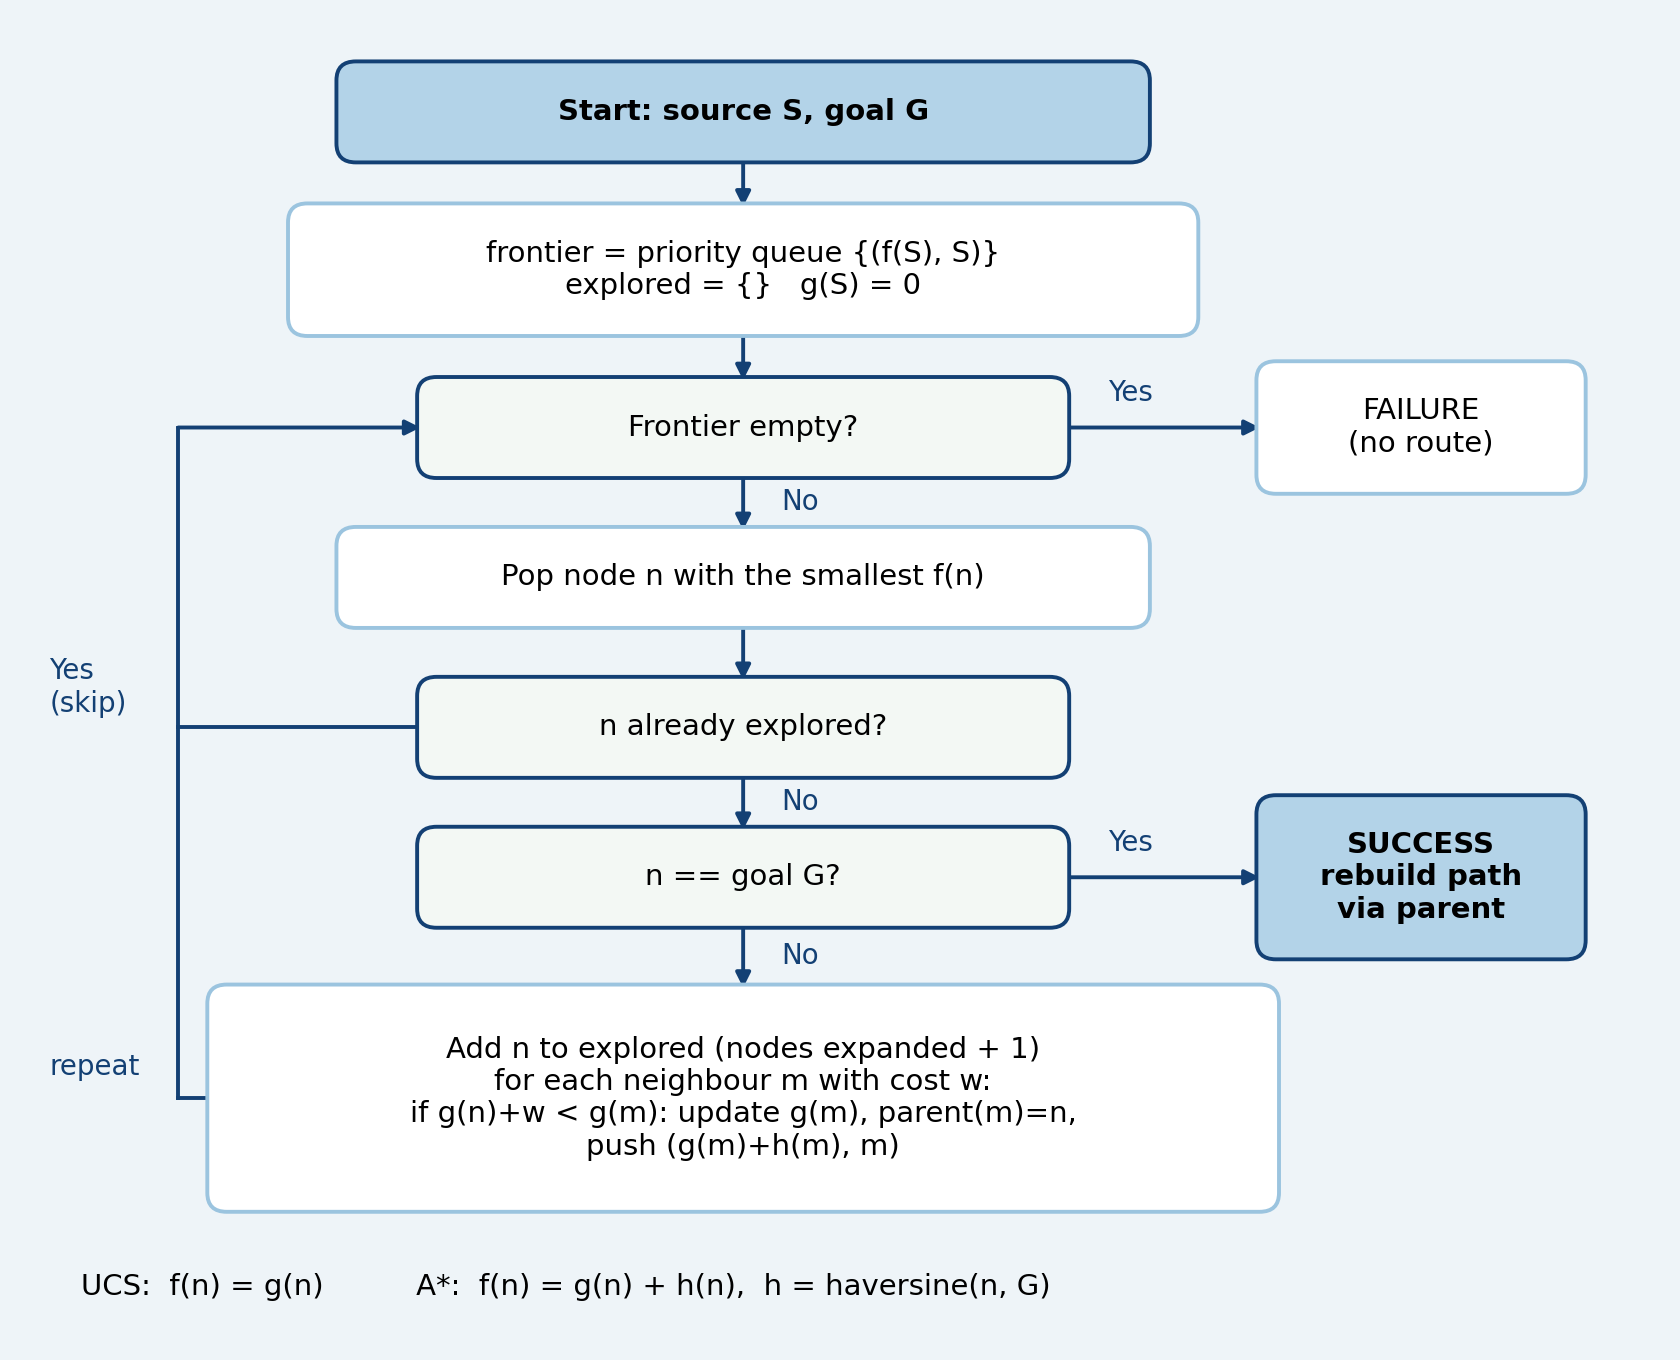

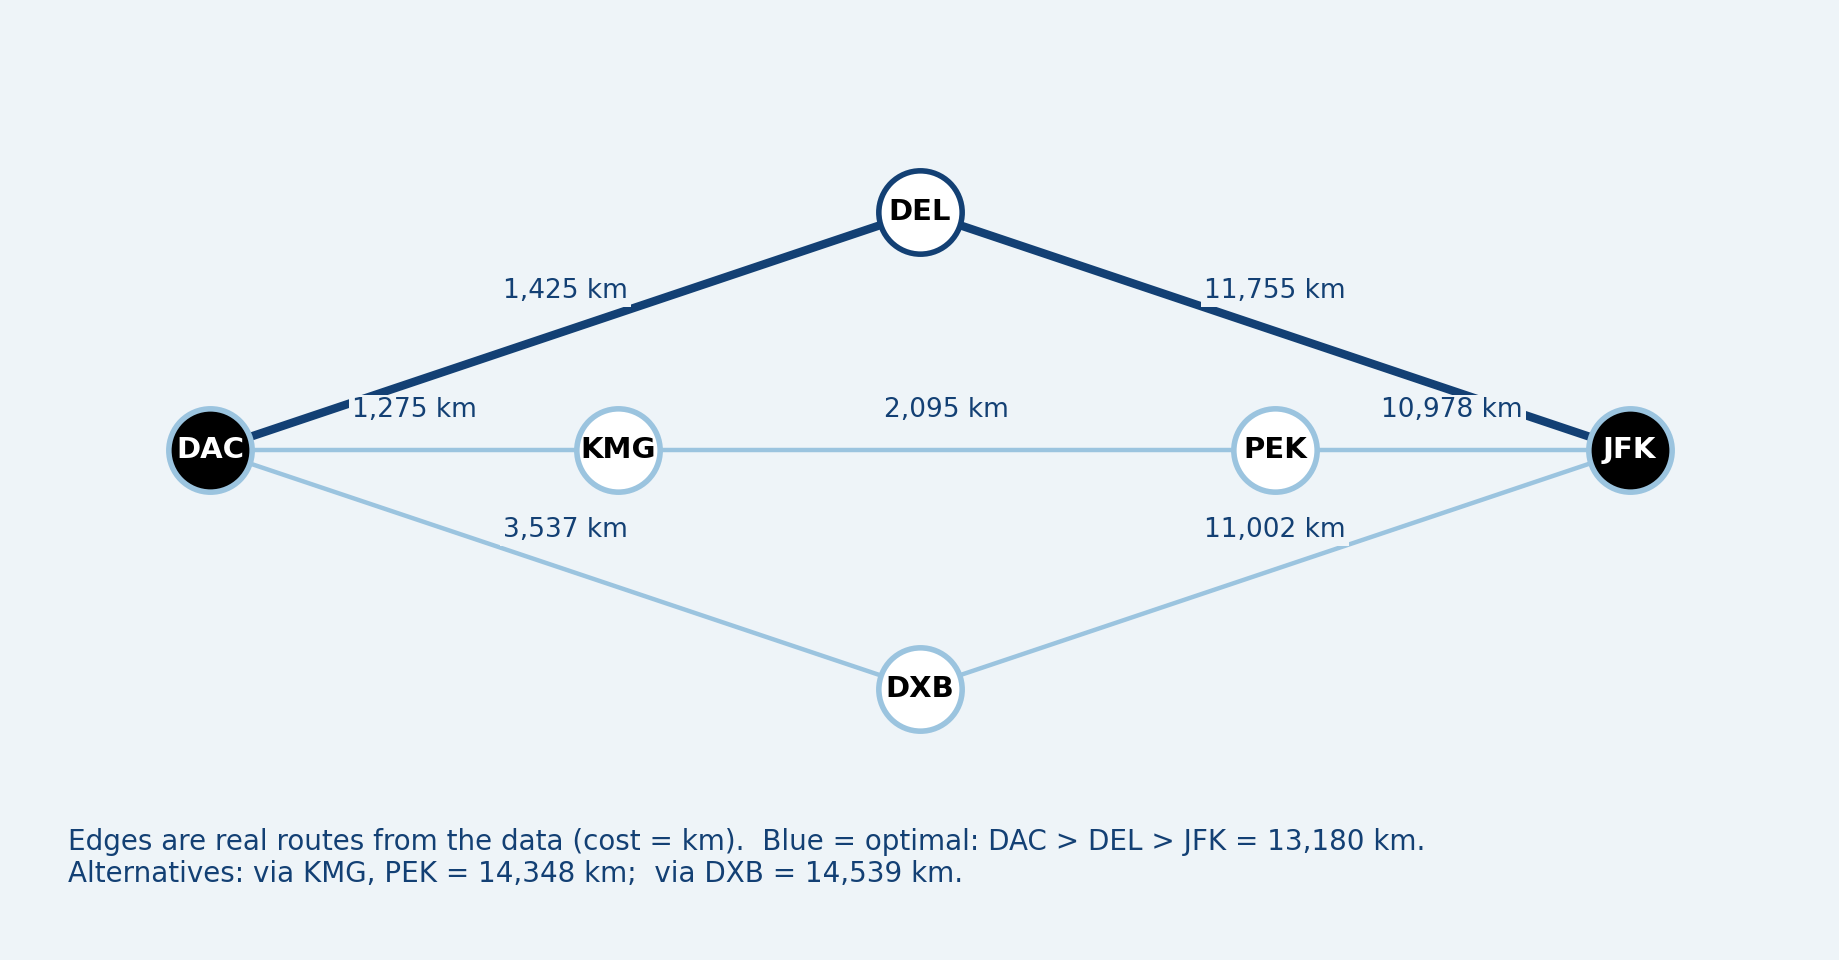

In [ ]:
from IPython.display import Image, display
for f in ["fig_nodes_expanded.png", "fig_time_memory.png", "fig_random_scatter.png",
          "fig_search_process.png", "fig_routes_map.png", "fig_flowchart.png", "fig_state_space.png"]:
    display(Image(f, width=700))